# Preparing Sectors

This notebook builds **`stocks_sect.parquet`**: one row per stock and day, with the stock's sector, its daily return, its rolling volatility and its weight inside its sector. It covers each stock's **full history**; every chapter that uses it (Chapters 1 to 5 and the Strategy Picker of Chapter 6) picks its own time window.

- **Inputs:** `data_processed/stocks_clean.parquet` and `metadata_clean.parquet`.
- **Output:** `data_processed/stocks_sect.parquet`.

**How sector series are built:** a sector's return (or volatility) on a day is the weighted average of its stocks' returns (or volatilities) that day. A stock's weight is its share of the sector's **dollar volume** that day (`Close × Volume`). Dollar volume reflects how much money trades in a stock; share volume alone would let a cheap stock with many shares traded outweigh a large company.

**Contents**
1. Setup
2. Stocks with a sector
3. Daily returns
4. Rolling volatility
5. Minimum history
6. Sector weights
7. Quick look at sector volatility
8. Export

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.utils.sector_panel import (
    add_daily_returns,
    add_rolling_volatility,
    add_sector_weights,
    attach_sectors,
    filter_window,
    sector_series,
)

PROCESSED_DIR = Path("data_processed")

END_DATE = "2020-04-01"    # last date of the price data
MIN_ROWS = 252             # at least one year of prices
RETURN_CAP = 0.5           # daily returns beyond ±50% are capped (see section 3)
VOL_WINDOWS = (20, 60, 120)  # ~1, 3 and 6 months of trading days

## 2. Stocks with a sector

Only stocks with a verified sector in the metadata are kept.

In [2]:
stocks = pd.read_parquet(
    PROCESSED_DIR / "stocks_clean.parquet",
    columns=["Date", "Symbol", "Close", "Adj Close", "Volume"],
)
meta = pd.read_parquet(PROCESSED_DIR / "metadata_clean.parquet")

panel = attach_sectors(stocks, meta)
print(f"Stocks in stocks_clean: {stocks['Symbol'].nunique()}")
print(f"Stocks with a sector:   {panel['Symbol'].nunique()}")

Stocks in stocks_clean: 5262
Stocks with a sector:   2991


## 3. Daily returns

`Return` is the simple daily return of `Adj Close`. Simple (not log) returns are used here because a sector's return is a weighted average of its stocks' simple returns.

A daily move beyond ±50% is capped at ±50%. Such moves are rare, and a single one would dominate a 20-day volatility. The count below shows how many returns are affected.

In [3]:
panel, n_capped = add_daily_returns(panel, price_col="Adj Close", cap=RETURN_CAP)
n_returns = panel["Return"].notna().sum()
print(f"Capped returns: {n_capped:,} of {n_returns:,} ({n_capped / n_returns:.4%})")

Capped returns: 2,872 of 14,157,884 (0.0203%)


## 4. Rolling volatility

`RollingVol{N}` is the standard deviation of a stock's daily returns over its last N trading days, for N = 20, 60 and 120. It is NaN for a stock's first N days.

In [4]:
panel = add_rolling_volatility(panel, windows=VOL_WINDOWS)
panel[[f"RollingVol{n}" for n in VOL_WINDOWS]].describe()

,RollingVol20,RollingVol60,RollingVol120
count,1.410107e+07,1.398190e+07,1.380419e+07
mean,2.489877e-02,2.568496e-02,2.602783e-02
std,2.073418e-02,1.914021e-02,1.844802e-02
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.232975e-02,1.362335e-02,1.417571e-02
50%,1.906839e-02,2.035006e-02,2.091024e-02
75%,3.042340e-02,3.156325e-02,3.206199e-02
max,3.601849e-01,3.122052e-01,2.687313e-01


## 5. Minimum history

Keep the stocks with at least `MIN_ROWS` days (one year) of prices: shorter series give unreliable volatilities and weights.

In [5]:
panel = filter_window(panel, None, END_DATE, MIN_ROWS)
print(f"Stocks kept: {panel['Symbol'].nunique()}, rows: {len(panel):,}")

panel.groupby("Sector")["Symbol"].nunique().sort_values(ascending=False).rename("stocks").to_frame()

Stocks kept: 2872, rows: 14,143,376


,stocks
Sector,
Financial Services,733
Healthcare,405
Technology,360
Industrials,338
Consumer Cyclical,288
Real Estate,168
Basic Materials,143
Energy,134
Consumer Defensive,124


## 6. Sector weights

- `DollarVolume` = `Close × Volume` (both adjusted for splits only, so this is the money actually traded).
- `Weight` = the stock's share of its sector's dollar volume that day, among stocks that have a return that day. Summing `Weight × Return` over a sector gives the sector's return.
- `WeightedVol{N}` = the same kind of weight (among stocks that have a `RollingVol{N}` that day) × `RollingVol{N}`. Summing it over a sector gives the sector's volatility.

Stocks without a value on a day get no weight that day, so the weights that are used always add up to 1.

In [6]:
panel = add_sector_weights(panel, windows=VOL_WINDOWS)

weight_sums = panel.groupby(["Date", "Sector"])["Weight"].sum(min_count=1).dropna()
print(f"Weight sums per (Date, Sector) with at least one return: min {weight_sums.min():.6f}, max {weight_sums.max():.6f}")

Weight sums per (Date, Sector) with at least one return: min 1.000000, max 1.000000


## 7. Quick look at sector volatility

Sector 60-day volatility, one panel per sector, as a sanity check (the chapters analyse these series in detail).

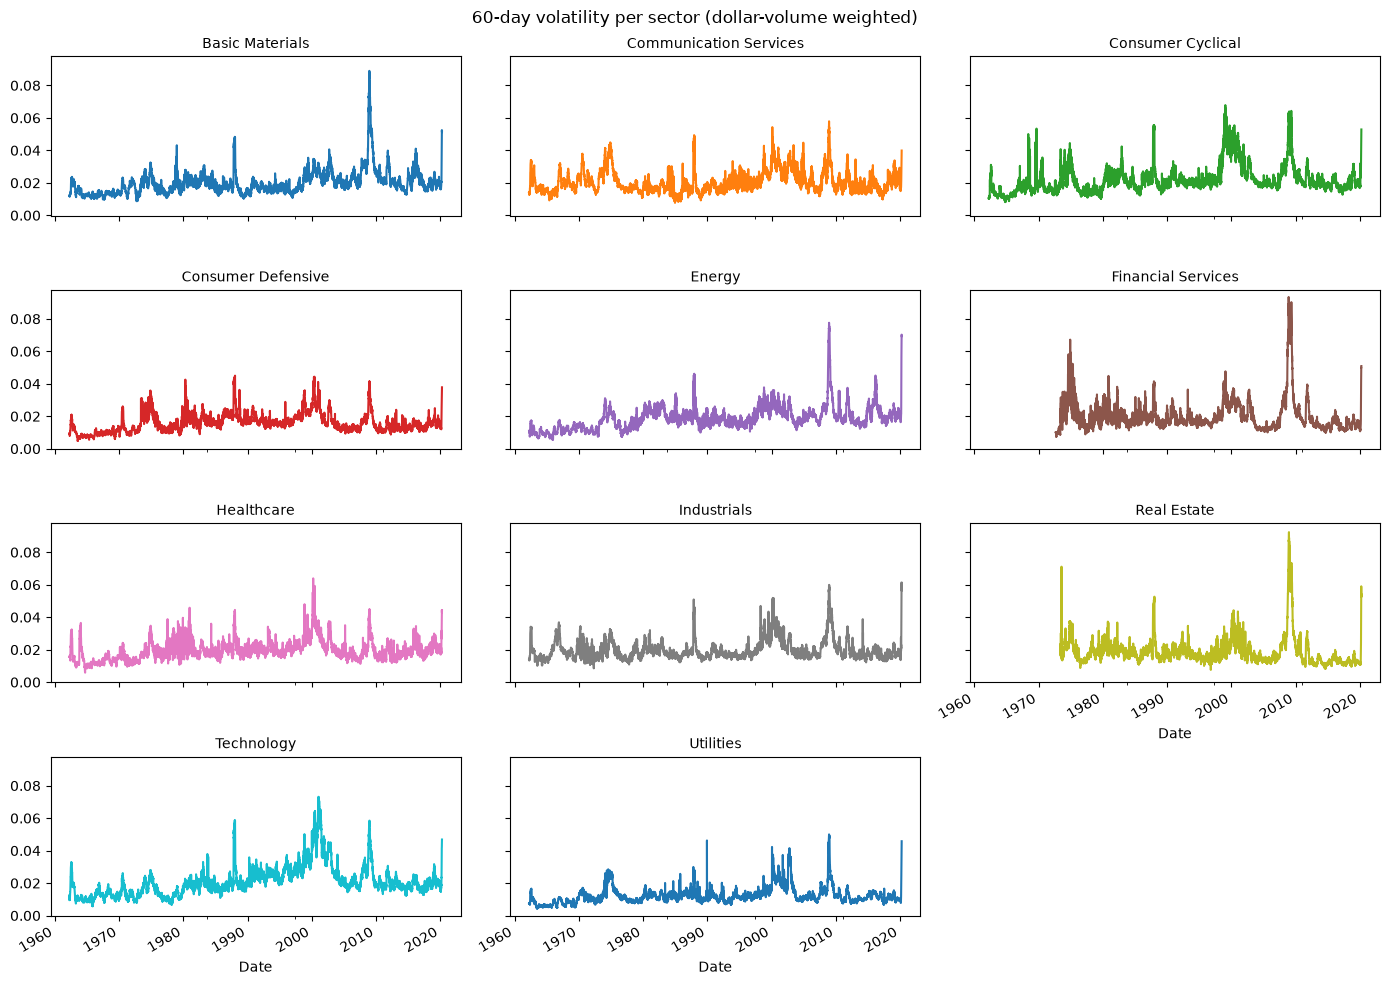

In [7]:
vol60 = sector_series(panel, "WeightedVol60")

axes = vol60.plot(subplots=True, layout=(4, 3), figsize=(14, 10), sharex=True, sharey=True, legend=False)
for ax, sector in zip(axes.flat, vol60.columns):
    ax.set_title(sector, fontsize=10)
for ax in axes.flat[len(vol60.columns):]:
    ax.set_visible(False)
plt.suptitle("60-day volatility per sector (dollar-volume weighted)")
plt.tight_layout()
plt.show()

## 8. Export

`data_processed/stocks_sect.parquet`, the only sector table: every chapter that needs stock-level sector data reads it.

In [8]:
columns = (
    ["Date", "Symbol", "Sector", "Close", "Adj Close", "Volume", "DollarVolume", "Return", "Weight"]
    + [f"RollingVol{n}" for n in VOL_WINDOWS]
    + [f"WeightedVol{n}" for n in VOL_WINDOWS]
)
stocks_sect = panel[columns].sort_values(["Symbol", "Date"]).reset_index(drop=True)
stocks_sect.to_parquet(PROCESSED_DIR / "stocks_sect.parquet", index=False)

print(f"Saved data_processed/stocks_sect.parquet: {stocks_sect['Symbol'].nunique()} stocks, {len(stocks_sect):,} rows")

Saved data_processed/stocks_sect.parquet: 2872 stocks, 14,143,376 rows
